In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Load source data and results data frame

In [ ]:
# load fid
raw_data = pd.read_csv('sample_data/flowmod_C2C005_FID.csv', sep=',', names=['RT', 'FID'])
raw_data.head() 

,RT,FID
0,0.000326,2.407383
1,0.000659,2.407063
2,0.000993,2.405869
3,0.001326,2.404210
4,0.001659,2.402816


In [ ]:
results_df = pd.read_csv('sample_data/Flow_C2C-005_results.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1


### Get DBE

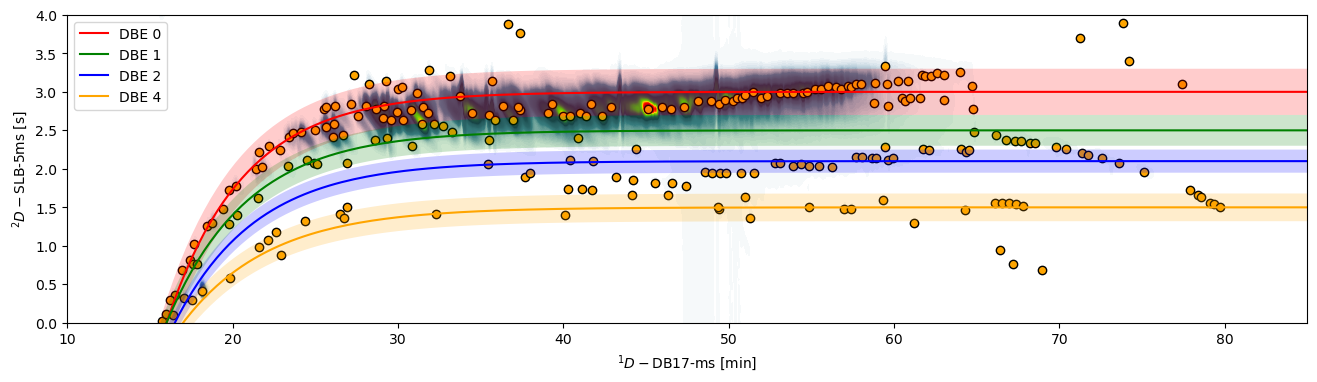

In [37]:
dbe0 = c2c.DBELine(0, 3.0, 35, 16, 0.05)
dbe1 = c2c.DBELine(1, 2.5, 35, 16, 0.05)
dbe2 = c2c.DBELine(2, 2.1, 35, 16.5, 0.05)
dbe4 = c2c.DBELine(4, 1.5, 35, 17, 0.05)

xmin = 10
xmax = 85
ymin = 0
ymax = 4

show_tolerance = True

fig, ax = plt.subplots(figsize=(16, 4))

c2c.plot2d(fig, ax, raw_data['RT'].values, raw_data['FID'].values,
           mod_time=4,
           shift=1.5, 
           color_range=(0, 90),
           cbar=False,
           axis_labels=('DB17-ms', 'SLB-5ms'),
           solvent_cut=0)

ax.scatter(results_df['RT 1d (min)'], results_df['RT 2d (s)'],
           color='orange', edgecolors='black')

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# plot lines
x = np.linspace(xmin, xmax, num=200)

dbe0.plotLine(ax, x, 0.3, 'DBE 0', 'red', show_tolerance=show_tolerance)
dbe1.plotLine(ax, x, 0.2, 'DBE 1', 'green', show_tolerance=show_tolerance)
dbe2.plotLine(ax, x, 0.15,  'DBE 2', 'blue', show_tolerance=show_tolerance)
dbe4.plotLine(ax, x, 0.18, 'DBE 4', 'orange', show_tolerance = show_tolerance)

ax.legend()
# ax.grid(color='black')

plt.show()

In [38]:
results_df['DBE'] = c2c.getDBE(results_df, [dbe0, dbe1, dbe2, dbe4])
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI,DBE
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1,1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1,0
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1,0
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1,2
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1,2


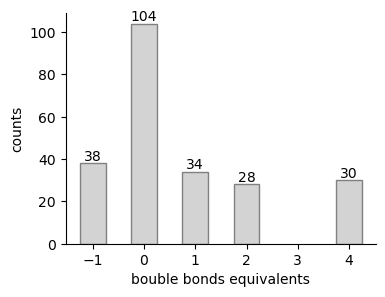

In [39]:
# bar plot

dbe_counts = np.unique(results_df['DBE'], return_counts=True)
    
fig, ax = plt.subplots(figsize=(4, 3))

plot = ax.bar(dbe_counts[0], dbe_counts[1], width=0.5, color='lightgray', edgecolor='gray')
ax.bar_label(plot)
ax.set_ylabel('counts')
ax.set_xlabel('bouble bonds equivalents')
ax.set_xticks(range(-1, 5))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

### Start CNum object and create retention time ranges

In [40]:
cnum_class = c2c.CNum()
cnum_class.create_cnumItem('0', cnum_list=[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
                           mz_list= [86, 100, 114, 128, 142, 156, 170, 184, 198, 212, 226],
                           c_ranges = [[(15.6, 0.05), (16.3, 0.4)],
                                       [(16.3, 0.45), (17, 0.75)], 
                                       [(16.6, 0.7), (18.5, 1.2)],
                                       [(17, 1.1), (21, 1.7)],
                                       [(18, 1.55), (25, 2.2)],
                                       [(21, 2.2), (30, 2.5)],
                                       [(24, 2.75), (35, 2.5)],
                                       [(27, 3.05), (40, 2.6)],
                                       [(32, 3.15), (45, 2.65)],
                                       [(39, 3.1), (50, 2.75)],
                                       [(43, 3.2), (55, 2.8)]
                           ])

# display(cnum_class.cnum_ranges)

In [41]:
cnum_class.create_cnumItem('2', cnum_list=[9, 10, 11],
                           mz_list=[109, 123, 137],
                           c_ranges=[[(25, 2.1),(29, 2.15)],
                                     [(30, 2.4), (35, 2.2)],
                                     [(35, 2.5), (40, 2.2)]
                           ])

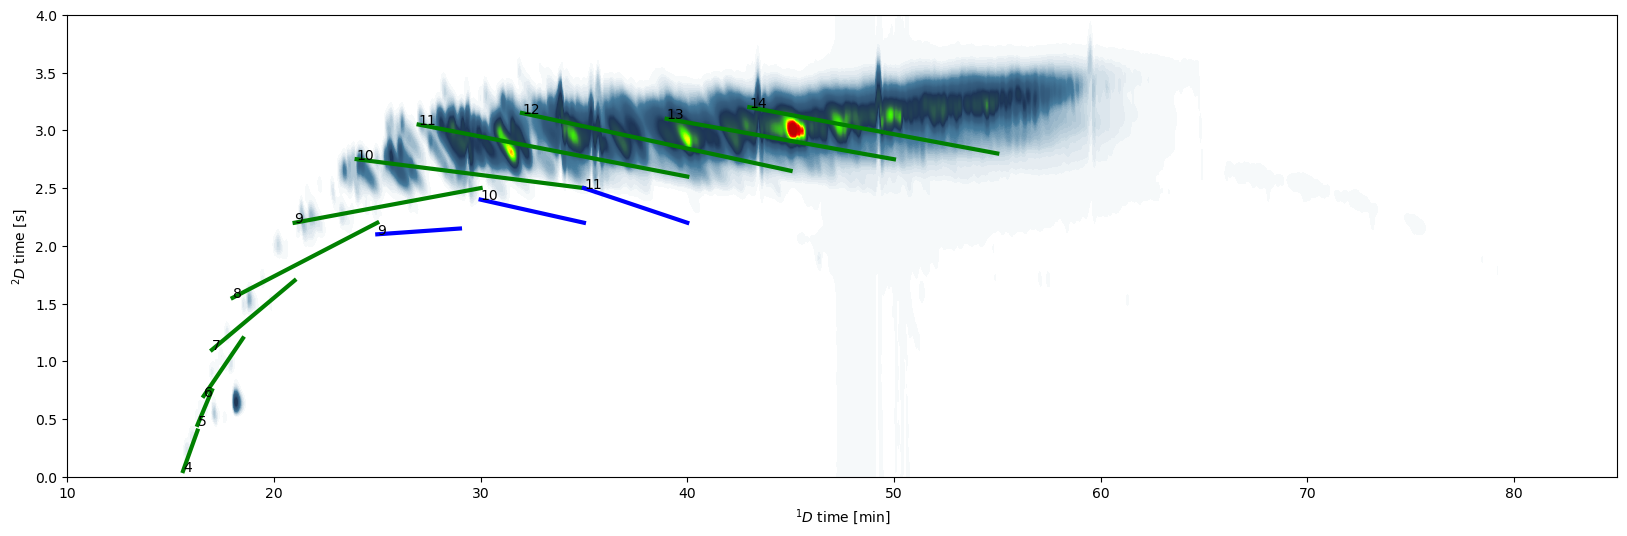

In [42]:
# draw lines

fig, ax = plt.subplots(figsize=(20, 6))

c2c.plot2d(fig, ax, raw_data['RT'].values, raw_data['FID'].values,
           mod_time=4, shift=1.7,
           cbar=False, color_range=(0, 90))

ax.set_xlim(10, 85)
ax.set_ylim()

color_list = ['green', 'blue', 'orange']

for i, dbe in enumerate(cnum_class.cnum_ranges.keys()):

       for k in cnum_class.cnum_ranges[dbe].keys():
              ax.plot(cnum_class.cnum_ranges[dbe][k]['rt1'],
              cnum_class.cnum_ranges[dbe][k]['rt2'], color=color_list[i], lw=3)
              ax.text(cnum_class.cnum_ranges[dbe][k]['rt1'][0],
              cnum_class.cnum_ranges[dbe][k]['rt2'][0],
              s=str(k))

plt.show()


In [43]:
results_df['CNum (RT)'] = cnum_class.get_cnum(results_df)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons,LRI,DBE,CNum (RT)
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1,-1,1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1,-1,0,4
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1,-1,0,5
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1,-1,2,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1,-1,2,-1


In [ ]:
# export data frame
results_df.to_csv('sample_data/Flow_C2C-005_results.csv', sep=',', index=False)